# Pediatric Critical Care Analytics — Phase 4: Revision analyses

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
SEED = 42
rng = np.random.default_rng(SEED)
MS = {}          # manuscript numbers, key -> (description, value)
def put(key, desc, value): MS[key] = (desc, value)

VITALS = ["temp", "pulse", "hr", "rr", "spo2", "dbp", "sbp"]
LABS = ["lactate", "creatinine", "ph", "crp", "hemoglobin", "glucose", "sodium", "potassium", "wbc", "platelet"]
target = "HOSPITAL_EXPIRE_FLAG"
categorical_cols = ["age_group", "GENDER", "FIRST_CAREUNIT", "primary_diagnosis_chapter"]

In [2]:
try:
    features
    print("Using `features` already in memory.")
except NameError:
    features = pd.read_pickle("features_admission_level.pkl")
    print("Loaded features_admission_level.pkl")

adm = pd.read_csv("ADMISSIONS.csv", usecols=["SUBJECT_ID", "HADM_ID", "HOSPITAL_EXPIRE_FLAG"])
icu = pd.read_csv("ICUSTAYS.csv", usecols=["SUBJECT_ID", "HADM_ID"])
print(f"features: {features.shape[0]:,} admissions x {features.shape[1]} columns "
      f"(expected 13,449 x 61); mortality {features[target].mean()*100:.2f}%")

Loaded features_admission_level.pkl
features: 13,449 admissions x 61 columns (expected 13,449 x 61); mortality 7.22%


## 1. Reconcile admission-level and stay-level counts (Reviewer 2, point 1)

`HOSPITAL_EXPIRE_FLAG` is an *admission* attribute. Joining `ICUSTAYS` to `ADMISSIONS` copies it onto every ICU stay
of a multi-stay admission, so a death is counted once per stay, not once per admission.

In [3]:
stay = icu.merge(adm, on=["SUBJECT_ID", "HADM_ID"], how="left")
rec = pd.DataFrame({
    "cohort": ["Admission-level (one row per HADM_ID)", "Stay-level (one row per ICU stay)"],
    "n": [len(adm), len(stay)],
    "deaths": [int(adm[target].sum()), int(stay[target].sum())],
})
rec["mortality_%"] = (rec["deaths"] / rec["n"] * 100).round(2)
display(rec)

per_adm = stay.groupby("HADM_ID")[target].agg(stays="size", flagged="sum")
multi = per_adm[per_adm["stays"] > 1]
extra_deaths = int((multi["flagged"] - (multi["flagged"] > 0)).sum())   # deaths counted beyond one per admission
print(f"Admissions with >1 ICU stay: {len(multi):,}  (extra stays: {len(stay) - len(adm):,})")
print(f"Deaths counted more than once because of repeat stays: {extra_deaths}")
print(f"Stay-level deaths - admission-level deaths = {rec.deaths[1] - rec.deaths[0]}  ->  "
      f"{'RECONCILED' if rec.deaths[1] - rec.deaths[0] == extra_deaths else 'DOES NOT RECONCILE - investigate'}")

,cohort,n,deaths,mortality_%
0,Admission-level (one row per HADM_ID),13449,971,7.22
1,Stay-level (one row per ICU stay),13941,999,7.17


Admissions with >1 ICU stay: 377  (extra stays: 492)
Deaths counted more than once because of repeat stays: 28
Stay-level deaths - admission-level deaths = 28  ->  RECONCILED


## 2. Acuity-adjusted unit comparison (Reviewer 1, point 1)

Admission-level cohort (first ICU stay per admission; one row per child, so no repeated-stay duplication), logistic regression
of in-hospital death on care unit (reference CICU), with standard errors clustered by patient.

* **Crude** - care unit only.
* **Model 1** - + age (continuous) + primary-diagnosis chapter (chapters with <50 admissions pooled). Mirrors the diagnostic notebook,
  but on the admission-level cohort.
* **Model 2** - Model 1 + first-24-hour physiology: mean of each of the 7 vitals and 10 labs (clipped to the cohort 1st-99th percentile,
  median-imputed, standardized), the abnormal-lab count, the number of vitals / labs measured, and whether lactate and pH were measured.

The vasopressor flag is deliberately **excluded** from Model 2: it is not restricted to the first 24 h (see Section 6) and is a treatment, not baseline acuity.

In [4]:
acu = features.merge(adm[["HADM_ID", "SUBJECT_ID"]], on="HADM_ID", how="left")
for n in VITALS + LABS:
    acu[f"meas_{n}"] = acu[f"mean_{n}"].notna().astype(int)
acu["n_vitals_measured"] = acu[[f"meas_{v}" for v in VITALS]].sum(axis=1)
acu["n_labs_measured"] = acu[[f"meas_{l}" for l in LABS]].sum(axis=1)
acu["any_vitals"] = (acu["n_vitals_measured"] > 0).astype(int)
acu["any_labs"] = (acu["n_labs_measured"] > 0).astype(int)

CONT = [f"mean_{n}" for n in VITALS + LABS] + ["n_abnormal_labs_24h"]
clip_ref = {c: (acu[c].quantile(0.01), acu[c].quantile(0.99)) for c in CONT}

print("First-24h measurement coverage by care unit (% of admissions):")
display(acu.groupby("FIRST_CAREUNIT")[["any_vitals", "any_labs"]].mean().mul(100).round(1)
        .join(acu.groupby("FIRST_CAREUNIT").size().rename("n_admissions")))

def build_design(df, model):
    d = df.dropna(subset=["age_years"]).copy()
    X = pd.get_dummies(d["FIRST_CAREUNIT"], prefix="unit").drop(columns="unit_CICU").astype(float)
    if model in ("m1", "m2"):
        X["age_years"] = d["age_years"]
        vc = d["primary_diagnosis_chapter"].value_counts()
        grp = pd.Series(np.where(d["primary_diagnosis_chapter"].isin(vc[vc >= 50].index),
                                 d["primary_diagnosis_chapter"], "Other (low volume)"), index=d.index)
        X = X.join(pd.get_dummies(grp, prefix="dx", drop_first=True).astype(float))
    if model == "m2":
        for c in CONT:
            lo, hi = clip_ref[c]
            s = d[c].clip(lo, hi)
            s = s.fillna(s.median())
            X[c] = (s - s.mean()) / (s.std() if s.std() > 0 else 1.0)
        for c in ["n_vitals_measured", "n_labs_measured", "meas_lactate", "meas_ph"]:
            X[c] = d[c].astype(float)
    X = X.loc[:, X.std() > 0]
    return d, sm.add_constant(X, has_constant="add"), d[target].astype(int)

def fit(df, model):
    d, X, y = build_design(df, model)
    res = sm.Logit(y, X).fit(disp=False, maxiter=200, cov_type="cluster",
                             cov_kwds={"groups": d["SUBJECT_ID"].values})
    return res, X, y

def unit_or(res):
    ci = res.conf_int()
    t = pd.DataFrame({"odds_ratio": np.exp(res.params), "ci_low": np.exp(ci[0]),
                      "ci_high": np.exp(ci[1]), "p": res.pvalues})
    return t.filter(like="unit_", axis=0)

fits = {m: fit(acu, m) for m in ["crude", "m1", "m2"]}
tabs = {m: unit_or(fits[m][0]) for m in fits}
for m in fits:
    print(f"{m}: n = {int(fits[m][0].nobs):,}, apparent ROC-AUC = {roc_auc_score(fits[m][2], fits[m][0].predict(fits[m][1])):.3f}")

order = ["General ICU", "PICU", "NICU", "SICU"]
fmt = lambda r: f"{r.odds_ratio:.2f} ({r.ci_low:.2f}\u2013{r.ci_high:.2f})"
table4 = pd.DataFrame({
    "Care unit": order,
    "Crude OR (95% CI)": [fmt(tabs["crude"].loc[f"unit_{u}"]) for u in order],
    "Model 1: age + diagnosis": [fmt(tabs["m1"].loc[f"unit_{u}"]) for u in order],
    "Model 2: + first-24h acuity": [fmt(tabs["m2"].loc[f"unit_{u}"]) for u in order],
})
print("\nTABLE 4 (paste into the manuscript):")
display(table4)
print("p-values, Model 2:"); display(tabs["m2"][["p"]].round(4))

g1, g2 = tabs["m1"].loc["unit_General ICU"], tabs["m2"].loc["unit_General ICU"]
put("A1", "GICU vs CICU OR, Model 1 (admission level)", f"{g1.odds_ratio:.2f}")
put("A2", "GICU vs CICU OR, Model 2 (acuity-adjusted)", f"{g2.odds_ratio:.2f}")
put("A2_lo", "Model 2 GICU OR, 95% CI low", f"{g2.ci_low:.2f}")
put("A2_hi", "Model 2 GICU OR, 95% CI high", f"{g2.ci_high:.2f}")
put("A3", "PICU OR, Model 2", f"{tabs['m2'].loc['unit_PICU'].odds_ratio:.2f}")
put("A4", "NICU OR, Model 2", f"{tabs['m2'].loc['unit_NICU'].odds_ratio:.2f}")
put("A5", "SICU OR, Model 2", f"{tabs['m2'].loc['unit_SICU'].odds_ratio:.2f}")
put("A6", "Apparent (in-sample) ROC-AUC, Model 1", f"{roc_auc_score(fits['m1'][2], fits['m1'][0].predict(fits['m1'][1])):.3f}")
put("A7", "Apparent (in-sample) ROC-AUC, Model 2", f"{roc_auc_score(fits['m2'][2], fits['m2'][0].predict(fits['m2'][1])):.3f}")

First-24h measurement coverage by care unit (% of admissions):


,any_vitals,any_labs,n_admissions
FIRST_CAREUNIT,,,
CICU,91.1,94.4,2638
General ICU,2.5,74.3,2725
NICU,86.6,96.6,3205
PICU,89.9,95.6,2084
SICU,95.9,95.3,2797


crude: n = 13,449, apparent ROC-AUC = 0.704
m1: n = 13,449, apparent ROC-AUC = 0.750
m2: n = 13,449, apparent ROC-AUC = 0.867

TABLE 4 (paste into the manuscript):


,Care unit,Crude OR (95% CI),Model 1: age + diagnosis,Model 2: + first-24h acuity
0,General ICU,8.81 (6.58–11.79),9.74 (7.05–13.45),3.79 (2.46–5.85)
1,PICU,5.32 (3.91–7.24),5.07 (3.60–7.14),3.95 (2.60–5.98)
2,NICU,3.93 (2.91–5.32),3.26 (2.25–4.73),2.32 (1.43–3.75)
3,SICU,1.01 (0.70–1.48),1.11 (0.75–1.65),1.69 (1.07–2.69)


p-values, Model 2:


,p
unit_General ICU,0.0000
unit_NICU,0.0006
unit_PICU,0.0000
unit_SICU,0.0246


In [5]:
# Robustness: restrict Model 2 to admissions that actually have first-24h vitals (physiology not imputed wholesale)
sub = acu[acu["any_vitals"] == 1]
res_s, X_s, y_s = fit(sub, "m2")
gs = unit_or(res_s).loc["unit_General ICU"]
print(f"Model 2, admissions with observed vitals only: n = {int(res_s.nobs):,}; "
      f"GICU OR {gs.odds_ratio:.2f} ({gs.ci_low:.2f}-{gs.ci_high:.2f}), p = {gs.p:.4f}")
display(unit_or(res_s).round(3))
put("A9n", "n, Model 2 restricted to admissions with observed vitals", f"{int(res_s.nobs):,}")
put("A9", "GICU OR, Model 2 restricted (95% CI)", f"{gs.odds_ratio:.2f} ({gs.ci_low:.2f}\u2013{gs.ci_high:.2f})")

Model 2, admissions with observed vitals only: n = 9,804; GICU OR 9.56 (3.42-26.71), p = 0.0000


,odds_ratio,ci_low,ci_high,p
unit_General ICU,9.560,3.422,26.709,0.000
unit_NICU,2.170,1.216,3.871,0.009
unit_PICU,4.862,2.983,7.923,0.000
unit_SICU,1.647,0.971,2.793,0.064


**How to write the interpretation (`[[A_INTERP]]` in Section 5.1).** Compare `A1` with `A2` and look at the Model 2 confidence interval:
* CI still excludes 1 -> "attenuated but persistent" (or "essentially unchanged", if `A2` is close to `A1`);
* CI now includes 1 -> "no longer distinguishable from the CICU".

Whichever it is, keep the sentence in the Discussion that says the residual difference is **not** evidence of poorer care.

## 3. Re-fit the published mortality models (identical split and settings) + balancing check (Reviewer 2, point 2)

Settings copied from the predictive notebook: 75/25 split stratified by outcome (`random_state=42`); median imputation + scaling
for numerics, most-frequent imputation + one-hot for categoricals, all **inside a `Pipeline`, so they are fitted on the training set only**;
`class_weight="balanced"` for both models; RF = 300 trees, `max_depth=8`. **No resampling** (no under-sampling, over-sampling or SMOTE) is used anywhere.

In [6]:
numeric_cols = [c for c in features.columns
                if pd.api.types.is_numeric_dtype(features[c])
                and c not in [target, "los_icu_days", "HADM_ID"] and c not in categorical_cols]
X = features[numeric_cols + categorical_cols]
y = features[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEED, stratify=y)
print(f"Train {len(X_train):,} | Test {len(X_test):,} | train mortality {y_train.mean()*100:.2f}% | test mortality {y_test.mean()*100:.2f}%")
print("Train class counts:", y_train.value_counts().to_dict(), "| Test class counts:", y_test.value_counts().to_dict())

def make_prep(num, cat):
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore"))]), cat)])

def make_rf(class_weight="balanced", num=None, cat=None):
    return Pipeline([("prep", make_prep(num or numeric_cols, cat or categorical_cols)),
                     ("clf", RandomForestClassifier(n_estimators=300, max_depth=8, class_weight=class_weight,
                                                    random_state=SEED, n_jobs=-1))])

def make_lr(class_weight="balanced", num=None, cat=None):
    return Pipeline([("prep", make_prep(num or numeric_cols, cat or categorical_cols)),
                     ("clf", LogisticRegression(max_iter=2000, class_weight=class_weight))])

rf = make_rf().fit(X_train, y_train)
lr = make_lr().fit(X_train, y_train)
p_rf, p_lr = rf.predict_proba(X_test)[:, 1], lr.predict_proba(X_test)[:, 1]

print(f"\nLR  ROC-AUC {roc_auc_score(y_test, p_lr):.3f}  PR-AUC {average_precision_score(y_test, p_lr):.3f}   (paper: 0.840 / 0.308)")
print(f"RF  ROC-AUC {roc_auc_score(y_test, p_rf):.3f}  PR-AUC {average_precision_score(y_test, p_rf):.3f}   (paper: 0.876 / 0.394)")
if abs(roc_auc_score(y_test, p_rf) - 0.876) > 0.002 or abs(roc_auc_score(y_test, p_lr) - 0.840) > 0.002:
    print("WARNING: does not reproduce the published AUCs - check that `features` is the unmodified matrix from the predictive notebook.")

print("\nBalancing verification:")
print("  RF class_weight:", rf.named_steps["clf"].class_weight, "| LR class_weight:", lr.named_steps["clf"].class_weight)
print("  Rows in X_train after fitting pipeline:", len(X_train), "(unchanged -> no resampling)")

Train 10,086 | Test 3,363 | train mortality 7.22% | test mortality 7.23%
Train class counts: {0: 9358, 1: 728} | Test class counts: {0: 3120, 1: 243}

LR  ROC-AUC 0.840  PR-AUC 0.308   (paper: 0.840 / 0.308)
RF  ROC-AUC 0.880  PR-AUC 0.415   (paper: 0.876 / 0.394)

Balancing verification:
  RF class_weight: balanced | LR class_weight: balanced
  Rows in X_train after fitting pipeline: 10086 (unchanged -> no resampling)


In [7]:
# Effect of class weighting on ranking vs. calibration (same split)
rf_unw = make_rf(class_weight=None).fit(X_train, y_train)
p_unw = rf_unw.predict_proba(X_test)[:, 1]
print(f"RF unweighted: ROC-AUC {roc_auc_score(y_test, p_unw):.3f}, PR-AUC {average_precision_score(y_test, p_unw):.3f}, "
      f"Brier {brier_score_loss(y_test, p_unw):.4f}")
put("B1", "ROC-AUC, RF without class weights", f"{roc_auc_score(y_test, p_unw):.3f}")
put("B2", "PR-AUC, RF without class weights", f"{average_precision_score(y_test, p_unw):.3f}")

# Case-mix-only baseline (unit, age, age group, gender, diagnosis chapter) for the Discussion claim
cm_num, cm_cat = ["age_years"], categorical_cols
cm = make_lr(num=cm_num, cat=cm_cat).fit(X_train[cm_num + cm_cat], y_train)
p_cm = cm.predict_proba(X_test[cm_num + cm_cat])[:, 1]
print(f"Case-mix-only LR: ROC-AUC {roc_auc_score(y_test, p_cm):.3f}, PR-AUC {average_precision_score(y_test, p_cm):.3f}")
put("D1", "ROC-AUC, case-mix-only model (unit, age, gender, diagnosis chapter)", f"{roc_auc_score(y_test, p_cm):.3f}")

RF unweighted: ROC-AUC 0.888, PR-AUC 0.417, Brier 0.0526
Case-mix-only LR: ROC-AUC 0.738, PR-AUC 0.155


## 4. Calibration (Reviewer 1, point 2)

Metrics on the held-out test set: Brier score (with the no-skill reference `prevalence x (1 - prevalence)`), calibration intercept
(calibration-in-the-large, slope fixed at 1) and calibration slope (logistic regression of the outcome on the logit of the predicted risk),
expected calibration error (ECE, decile bins), plus a reliability plot. Both class-weighted models are assessed as fitted, and the RF is also
Platt-recalibrated using 5-fold cross-validation **inside the training set only**, then evaluated on the untouched test set.
Ideal values: intercept 0, slope 1, Brier low, ECE 0.

In [8]:
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

def cal_int_slope(y_true, p):
    z = logit(p)
    slope = sm.Logit(y_true, sm.add_constant(z)).fit(disp=False).params[1]
    citl = sm.GLM(y_true, np.ones((len(y_true), 1)), family=sm.families.Binomial(), offset=z).fit().params[0]
    return citl, slope

def ece(y_true, p, bins=10):
    d = pd.DataFrame({"y": y_true, "p": p, "b": pd.qcut(p, bins, duplicates="drop")})
    g = d.groupby("b", observed=True).agg(y=("y", "mean"), p=("p", "mean"), n=("y", "size"))
    return float((g["n"] * (g["y"] - g["p"]).abs()).sum() / g["n"].sum())

def boot_ci(fn, y_true, p, B=500):
    idx = np.arange(len(y_true)); out = []
    for _ in range(B):
        s = rng.choice(idx, len(idx), replace=True)
        if y_true[s].min() == y_true[s].max(): continue
        out.append(fn(y_true[s], p[s]))
    return np.percentile(out, [2.5, 97.5])

yt = y_test.values
rf_cal = CalibratedClassifierCV(make_rf(), method="sigmoid", cv=5).fit(X_train, y_train)
p_rfc = rf_cal.predict_proba(X_test)[:, 1]

models = {"Logistic regression": p_lr, "Random forest": p_rf, "Random forest, Platt-recalibrated": p_rfc}
rows = []
for name, p in models.items():
    citl, slope = cal_int_slope(yt, p)
    b_lo, b_hi = boot_ci(brier_score_loss, yt, p)
    rows.append({"model": name,
                 "ROC-AUC": roc_auc_score(yt, p),
                 "Brier": brier_score_loss(yt, p), "Brier 95% CI": f"{b_lo:.4f}-{b_hi:.4f}",
                 "cal. intercept": citl, "cal. slope": slope, "ECE": ece(yt, p),
                 "mean predicted": p.mean(), "observed": yt.mean()})
cal = pd.DataFrame(rows).set_index("model")
prev = yt.mean()
print(f"No-skill Brier (predict prevalence for everyone): {prev * (1 - prev):.4f}")
display(cal.round(4))

r = cal.loc
put("C0", "No-skill Brier score", f"{prev * (1 - prev):.3f}")
put("C1", "Brier, random forest", f"{r['Random forest','Brier']:.3f}")
put("C2", "Brier, logistic regression", f"{r['Logistic regression','Brier']:.3f}")
put("C3", "Calibration slope, random forest", f"{r['Random forest','cal. slope']:.2f}")
put("C4", "Calibration intercept, random forest", f"{r['Random forest','cal. intercept']:.2f}")
put("C5", "Mean predicted risk, random forest (observed = %.2f%%)" % (prev * 100), f"{r['Random forest','mean predicted']*100:.1f}%")
put("C6", "ECE, random forest", f"{r['Random forest','ECE']:.3f}")
put("C6b", "ECE, logistic regression", f"{r['Logistic regression','ECE']:.3f}")
put("C7", "Brier, recalibrated random forest", f"{r['Random forest, Platt-recalibrated','Brier']:.3f}")
put("C8", "Calibration slope, recalibrated random forest", f"{r['Random forest, Platt-recalibrated','cal. slope']:.2f}")
put("C9", "Calibration intercept, logistic regression", f"{r['Logistic regression','cal. intercept']:.2f}")
put("C10", "Calibration slope, logistic regression", f"{r['Logistic regression','cal. slope']:.2f}")
put("C11", "ROC-AUC, recalibrated random forest", f"{r['Random forest, Platt-recalibrated','ROC-AUC']:.3f}")

No-skill Brier (predict prevalence for everyone): 0.0670


,ROC-AUC,Brier,Brier 95% CI,cal. intercept,cal. slope,ECE,mean predicted,observed
model,,,,,,,,
Logistic regression,0.8404,0.1505,0.1440-0.1581,-2.6119,0.6216,0.2511,0.3234,0.0723
Random forest,0.8804,0.1126,0.1070-0.1177,-2.0051,1.3482,0.2074,0.2796,0.0723
"Random forest, Platt-recalibrated",0.8833,0.0525,0.0472-0.0579,0.0716,1.0300,0.0109,0.0686,0.0723


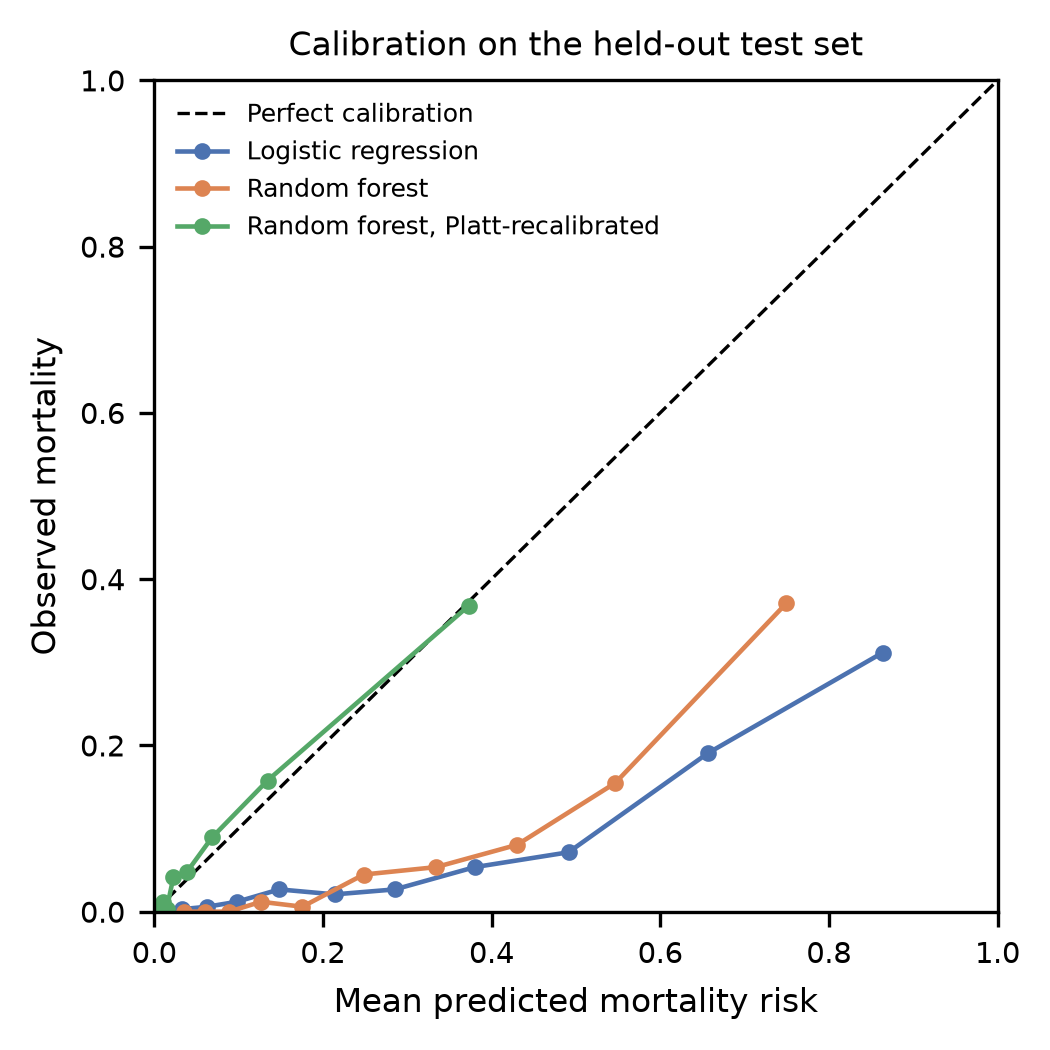

In [9]:
# Fig. 3 - reliability curves (sized for a single manuscript column)
fig, ax = plt.subplots(figsize=(3.6, 3.6), dpi=300)
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="Perfect calibration")
for (name, p), c in zip(models.items(), ["#4C72B0", "#DD8452", "#55A868"]):
    frac, mean_p = calibration_curve(yt, p, n_bins=10, strategy="quantile")
    ax.plot(mean_p, frac, marker="o", ms=3, lw=1.1, color=c, label=name)
ax.set_xlabel("Mean predicted mortality risk"); ax.set_ylabel("Observed mortality")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.legend(fontsize=6, loc="upper left", frameon=False)
ax.set_title("Calibration on the held-out test set", fontsize=8)
ax.tick_params(labelsize=7); ax.xaxis.label.set_size(8); ax.yaxis.label.set_size(8)
fig.tight_layout()
fig.savefig("fig3_calibration.png", dpi=300)
plt.show()

## 5. Is missingness informative, and does an explicit indicator help? (Reviewer 2, point 3)

(a) Mortality by measurement status; (b) add one binary "measured in the first 24 h" indicator per vital sign and per laboratory test (17 flags)
and refit both models on the same split; paired bootstrap for the AUC difference.

In [10]:
def mort_by(flag, label):
    ct = pd.crosstab(flag, y)
    chi2, p, _, _ = stats.chi2_contingency(ct)
    rate = y.groupby(flag).mean() * 100
    print(f"{label}: measured {rate.get(1, np.nan):.2f}% vs not measured {rate.get(0, np.nan):.2f}% "
          f"(n = {int((flag == 1).sum()):,} / {int((flag == 0).sum()):,}; chi-square p = {p:.2e})")
    return rate.get(1, np.nan), rate.get(0, np.nan), p

any_v = features[[f"mean_{v}" for v in VITALS]].notna().any(axis=1).astype(int)
any_l = features[[f"mean_{l}" for l in LABS]].notna().any(axis=1).astype(int)
fp = lambda p: "< 0.001" if p < 0.001 else f"= {p:.3f}"
v1, v0, pv = mort_by(any_v, "First-24h vitals ")
l1, l0, pl = mort_by(any_l, "First-24h labs   ")
put("M1", "Mortality (%) with first-24h vitals", f"{v1:.1f}%")
put("M2", "Mortality (%) without first-24h vitals", f"{v0:.1f}%")
put("M3", "p, vitals measured vs not (write as '< 0.001' or '= 0.xxx')", fp(pv))
put("M4", "Mortality (%) with first-24h labs", f"{l1:.1f}%")
put("M5", "Mortality (%) without first-24h labs", f"{l0:.1f}%")
put("M6", "p, labs measured vs not", fp(pl))

ind = pd.DataFrame({f"meas_{n}": features[f"mean_{n}"].notna().astype(int) for n in VITALS + LABS}, index=features.index)
X_ind = X.join(ind)
num_ind = numeric_cols + list(ind.columns)
Xi_train, Xi_test, _, _ = train_test_split(X_ind, y, test_size=0.25, random_state=SEED, stratify=y)
assert (Xi_test.index == X_test.index).all()

rf_i = make_rf(num=num_ind).fit(Xi_train, y_train)
lr_i = make_lr(num=num_ind).fit(Xi_train, y_train)
p_rfi, p_lri = rf_i.predict_proba(Xi_test)[:, 1], lr_i.predict_proba(Xi_test)[:, 1]

# paired bootstrap of the AUC difference (RF with indicators - RF without)
diffs = []
idx = np.arange(len(yt))
for _ in range(1000):
    s = rng.choice(idx, len(idx), replace=True)
    if yt[s].min() == yt[s].max(): continue
    diffs.append(roc_auc_score(yt[s], p_rfi[s]) - roc_auc_score(yt[s], p_rf[s]))
lo, hi = np.percentile(diffs, [2.5, 97.5])

summ = pd.DataFrame({
    "ROC-AUC": [roc_auc_score(yt, p_lr), roc_auc_score(yt, p_lri), roc_auc_score(yt, p_rf), roc_auc_score(yt, p_rfi)],
    "PR-AUC": [average_precision_score(yt, p) for p in (p_lr, p_lri, p_rf, p_rfi)]},
    index=["LR", "LR + missing indicators", "RF", "RF + missing indicators"])
display(summ.round(3))
print(f"AUC difference RF (with - without indicators): {np.mean(diffs):+.3f} (95% CI {lo:+.3f} to {hi:+.3f})")

put("M7", "ROC-AUC, RF + missing indicators", f"{roc_auc_score(yt, p_rfi):.3f}")
put("M8", "AUC difference (with - without indicators)", f"{roc_auc_score(yt, p_rfi) - roc_auc_score(yt, p_rf):+.3f}")
put("M9", "95% CI of the AUC difference", f"{lo:+.3f} to {hi:+.3f}")
put("M10", "PR-AUC, RF + missing indicators", f"{average_precision_score(yt, p_rfi):.3f}")

names = num_ind + list(rf_i.named_steps["prep"].named_transformers_["cat"].named_steps["ohe"].get_feature_names_out(categorical_cols))
imp = pd.Series(rf_i.named_steps["clf"].feature_importances_, index=names).sort_values(ascending=False)
print("\nTop-15 RF importances (impurity-based) with indicators; indicators marked *:")
display(imp.head(15).rename(lambda n: n + (" *" if n.startswith("meas_") else "")).round(4).to_frame("importance"))

First-24h vitals : measured 4.64% vs not measured 14.16% (n = 9,804 / 3,645; chi-square p = 8.76e-80)
First-24h labs   : measured 6.08% vs not measured 19.04% (n = 12,267 / 1,182; chi-square p = 2.86e-60)


,ROC-AUC,PR-AUC
LR,0.840,0.308
LR + missing indicators,0.863,0.357
RF,0.880,0.415
RF + missing indicators,0.884,0.407


AUC difference RF (with - without indicators): +0.004 (95% CI +0.000 to +0.007)

Top-15 RF importances (impurity-based) with indicators; indicators marked *:


,importance
mean_lactate,0.0929
max_lactate,0.0841
min_lactate,0.0620
min_hemoglobin,0.0531
mean_hemoglobin,0.0436
max_hemoglobin,0.0420
received_vasopressor,0.0407
min_rr,0.0279
n_abnormal_labs_24h,0.0228
mean_creatinine,0.0224


## 6. Sensitivity: vasopressor flag timing (added by the revision)

`received_vasopressor` is built from **any** matching row in `PRESCRIPTIONS` for the admission - it is not restricted to the first 24 h -
so it can encode treatment given after the prediction time. Refit the RF without it.

In [11]:
num_nv = [c for c in numeric_cols if c != "received_vasopressor"]
rf_nv = make_rf(num=num_nv).fit(X_train.drop(columns="received_vasopressor"), y_train)
p_nv = rf_nv.predict_proba(X_test.drop(columns="received_vasopressor"))[:, 1]
print(f"RF without vasopressor flag: ROC-AUC {roc_auc_score(yt, p_nv):.3f}, PR-AUC {average_precision_score(yt, p_nv):.3f} "
      f"(with flag: {roc_auc_score(yt, p_rf):.3f} / {average_precision_score(yt, p_rf):.3f})")
put("V1", "ROC-AUC, RF without vasopressor flag", f"{roc_auc_score(yt, p_nv):.3f}")

RF without vasopressor flag: ROC-AUC 0.868, PR-AUC 0.356 (with flag: 0.880 / 0.415)
